# 2.0 Preprocesamiento JobPath - Limpieza de Datos (Sesión 3)

**Objetivo:** Preprocesar el archivo CSV aplicando los temas de la Sesión 3: valores faltantes (MCAR, MAR, MNAR), duplicados, inconsistencias categóricas y valores atípicos (*outliers*).

**Enfoque:** Toda la lógica pesada se delega a los módulos ubicados en `scripts/ScriptsCsv/Preproccesing/`. Este cuaderno únicamente importa y llama a dichas funciones o clases.

---

## Reglas a seguir

- **Integridad del original:** Nunca se modifica ni se sobrescribe el CSV original. Todo el trabajo se realiza sobre una copia `df.copy()` en memoria.
- **Solo salida limpia:** Únicamente el archivo final limpio y *winsorizado* se escribe a disco, con un nombre diferente al original.
- **Valores atípicos:** Únicamente se utiliza el método **IQR** (`Q1 - 1.5*IQR` y `Q3 + 1.5*IQR`). Se aplica **winsorización con `clip()`**, **nunca** eliminación de filas. Los límites se calculan **antes** de cualquier imputación.
- **Duplicados:** Primero se eliminan duplicados exactos en todas las columnas (`keep='first'`). Después se analizan duplicados por la clave única `Resume_id`, mostrando las filas lado a lado para solicitar confirmación explícita antes de eliminarlos.
- **Valores faltantes:** Para cada columna con nulos se debe mostrar evidencia, proponer MCAR/MAR/MNAR, esperar confirmación explícita. Si es **MNAR**, se crea una columna indicadora `*_missing_mnar` y **NO** se imputa.
- **Fechas/Trimestres:** Las columnas `start_date` y `end_date` se encuentran en formato trimestral (`Q1`, `Q2`, `Q3`, `Q4`). Se tratan como texto y **nunca** se someten a winsorización.
- **Orden del pipeline:** Diagnóstico → Duplicados → Categorías → Valores faltantes (con confirmación) → Winsorización IQR → Validación

## 1. Configuración, rutas relativas e importaciones

**¿QUÉ SE HACE?** Se configuran las rutas relativas al proyecto `MineriaProtect/`, se añaden al `sys.path` y se importan todas las librerías y módulos del paquete `scripts/ScriptsCsv/Preproccesing/`.

**¿POR QUÉ?** Se requiere que todas las importaciones estén en la **primera celda de código**. Además, se usan rutas relativas para garantizar la reproducibilidad sin depender de rutas absolutas. Se fija una semilla aleatoria para asegurar resultados consistentes.

In [15]:
# Todas las importaciones en la primera celda
import sys
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

# Configuración de rutas relativas al proyecto MineriaProtect
cwd = Path.cwd()
project_root = cwd

if project_root.name == 'refactor':
    project_root = project_root.parent.parent
elif project_root.name == 'notebooks':
    project_root = project_root.parent
elif project_root.name == 'Preproccesing':
    # Por si se ejecuta desde dentro del paquete
    project_root = project_root.parent.parent.parent.parent
elif project_root.name != 'MineriaProtect':
    for p in [project_root] + list(project_root.parents):
        if p.name == 'MineriaProtect':
            project_root = p
            break

# Añadir raíz al path
sys.path.insert(0, str(project_root))

# Importaciones desde el paquete Preproccesing
from scripts.ScriptsCsv.Preproccesing import config, utils, io, diagnosis, duplicates, categories
from scripts.ScriptsCsv.Preproccesing import missing, imputation, outliers_iqr, validation, pipeline
from scripts.ScriptsCsv.Preproccesing.config import PipelineConfig, DEFAULT_CONFIG
from scripts.ScriptsCsv.Preproccesing.pipeline import PreprocessingPipeline
from scripts.ScriptsCsv.Preproccesing.utils import set_random_seed

# Semilla fija para reproducibilidad
set_random_seed(42)
np.random.seed(42)

print('Rutas configuradas correctamente')
print(f'Raíz del proyecto: {project_root}')
print(f'Módulos cargados desde: scripts/ScriptsCsv/Preproccesing/')
print('Semilla aleatoria: 42')

Rutas configuradas correctamente
Raíz del proyecto: c:\Users\User\Documents\JobPath\MineriaProtect
Módulos cargados desde: scripts/ScriptsCsv/Preproccesing/
Semilla aleatoria: 42


## 2. Carga del CSV

**¿QUÉ SE HACE?** Se carga el archivo `data/03_processed/empleos_limpio_con_competencias.csv` utilizando el módulo `io.py` con rutas relativas. Se crea una copia `df` para trabajar en memoria.

**¿POR QUÉ?** El archivo original **NO** debe ser modificado bajo ningún motivo. Trabajar con `.copy()` garantiza que cualquier transformación quede aislada y que el CSV de origen permanezca intacto tal como se solicitó.

In [16]:
# Inicializar pipeline
pipe = PreprocessingPipeline(config=DEFAULT_CONFIG)

# Carga segura del CSV (solo lectura)
df_raw = pipe.data_io.load_csv()
df = df_raw.copy()

print('Carga completada')
print(f'Forma del DataFrame: {df.shape[0]} filas x {df.shape[1]} columnas')

[IO] Loading: c:\Users\User\Documents\JobPath\MineriaProtect\data\03_processed\empleos_limpio_con_competencias.csv
[IO] File size: 274.47 MB
[IO] Loaded shape: (376567, 23)
Carga completada
Forma del DataFrame: 376567 filas x 23 columnas


## 3. Diagnóstico completo del dataset

**¿QUÉ SE HACE?** Se realiza un diagnóstico integral: dimensiones, tipos de datos, valores nulos por columna (conteo y porcentaje), duplicados exactos, duplicados por `Resume_id`, `describe()`, cardinalidad de variables categóricas, valores inusuales y posibles valores imposibles.

**¿POR QUÉ?** Antes de limpiar, es fundamental conocer el estado real de los datos. Este diagnóstico permite detectar problemas, justificar cada decisión posterior y documentar el punto de partida. Esto es el primer paso del enfoque **KDD/CRISP-DM** para la fase de preprocesamiento.

In [17]:
# Diagnóstico completo
diagnosis_results = pipe.run_diagnosis(df)

# Búsqueda heurística de posibles valores imposibles
impossible_findings = pipe.diagnoser.check_impossible_values(df)


🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍
ETAPA 1: DIAGNÓSTICO
🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍
DATASET DIAGNOSIS

[SHAPE] Rows: 376567, Columns: 23

[DTYPES]
object     12
float64     7
bool        3
int64       1
Name: count, dtype: int64

[NULLS] Columns with nulls: 13
                     null_count  null_percent
sin_tipo                 373387         99.16
knowledge                 64018         17.00
skills                    28306          7.52
occupation_label          28304          7.52
occupation_code           28304          7.52
n_skills_knowledge        28304          7.52
n_skills_sin_tipo         28304          7.52
veces_ese_oficio          28304          7.52
n_skills_essential        28304          7.52
n_skills_competence       28304          7.52
isco_group_label          25805          6.85
isco_level                25805          6.85
isco_group                25805          6.85

[DUPLICATES - EXACT] 0 rows
[DUPLICATES - BY Resume_id] Key not found in d

## 4. Tratamiento de duplicados

**¿QUÉ SE HACE?**
1. **Duplicados exactos:** Se eliminan aquellas filas idénticas en **TODAS** las columnas, usando `keep='first'`. Se reporta la cantidad eliminada.
2. **Duplicados por clave única `Resume_id`:** **NO** se eliminan automáticamente. Se agrupan por `Resume_id`, se muestran las filas lado a lado resaltando las columnas con diferencias y se solicita confirmación explícita. Si se aprueba, se aplicará `keep='first'`.

**¿POR QUÉ?** Existen casos donde pueden aparecer múltiples registros para el mismo `Resume_id`. Algunos pueden ser verdaderos (pluriempleo o registros diferenciados), otros pueden ser errores. Por ello, la clave `Resume_id` requiere revisión humana antes de cualquier eliminación.

In [18]:
# Paso 1 y 2: Duplicados
df = pipe.run_duplicates(df, remove_key_dups=False, key_dups_approved=False)

key_report = pipe.results.get('key_duplicates_report', {})
if key_report.get('found', False):
    print('\n' + '='*80)
    print('SE ENCONTRARON DUPLICADOS POR Resume_id - SE REQUIERE CONFIRMACIÓN')
    print('='*80)
    print('\nRevise los grupos mostrados arriba. Solo elimínelos si está seguro.')
    print('En caso de aprobación se usará keep="first".')
else:
    print('\nNo se encontraron duplicados por Resume_id.')


🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍
ETAPA 2: DUPLICADOS
🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍
STEP 1: EXACT DUPLICATES ACROSS ALL COLUMNS

[BEFORE] Shape: (376567, 23)
[EXACT DUPLICATES FOUND] 0 rows
[ACTION] None to remove
STEP 2: DUPLICATES BY UNIQUE KEY [Resume_id]
[ERROR] Key column 'Resume_id' not found in dataframe
[AVAILABLE COLUMNS] ['resume_id', 'start_date', 'end_date', 'university_level', 'matched_code', 'emparejado', 'occupation_code', 'occupation_label', 'isco_group', 'isco_group_label', 'isco_level', 'n_skills_essential', 'n_skills_competence', 'n_skills_knowledge', 'n_skills_sin_tipo', 'veces_ese_oficio', 'saber_skills', 'es_unknown_ocupacion', 'es_rescatado', 'es_vigente', 'skills', 'knowledge', 'sin_tipo']

No se encontraron duplicados por Resume_id.


**ACCIÓN REQUERIDA:** Si existen duplicados por `Resume_id`, analice los grupos. Para eliminarlos, cambie los valores a `True` en la siguiente celda y ejecútela.

In [19]:
# Solo ejecutar si APRUEBA la eliminación de duplicados por Resume_id
APPROVE_KEY_DUPLICATES = False
REMOVE_KEY_DUPLICATES = False

if REMOVE_KEY_DUPLICATES and APPROVE_KEY_DUPLICATES:
    print('Eliminando duplicados por Resume_id con keep="first"...')
    df, key_report2 = pipe.duplicate_handler.remove_key_duplicates(df, approved=True, keep='first')
    pipe.df = df
    print('Proceso completado.')
else:
    print('No se eliminaron duplicados por Resume_id (sin aprobación).')

No se eliminaron duplicados por Resume_id (sin aprobación).


## 5. Inconsistencias categóricas

**¿QUÉ SE HACE?** Se revisan las columnas de tipo `object` en busca de inconsistencias: espacios al inicio/final, mayúsculas/minúsculas mixtas, tildes, múltiples espacios. Las columnas `start_date` y `end_date` se excluyen por estar en formato trimestral.

**¿POR QUÉ?** Aunque se indica que el CSV viene teóricamente normalizado, siempre se debe verificar. Si se detectan inconsistencias reales, la normalización (`strip`, sin tildes, estandarización de mayúsculas/minúsculas) solo se aplicará con confirmación explícita.

In [20]:
# Análisis de categorías
df = pipe.run_categories(df, normalize=False, approved=False)
cat_report = pipe.results.get('categories_report', {})
print(f"\n¿Requiere normalización?: {cat_report.get('needs_normalization', False)}")


🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍
ETAPA 3: CATEGORÍAS
🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍
CATEGORICAL ANALYSIS
[NOTE] CSV is supposedly already normalized. Checking for inconsistencies...

[OK - start_date] 206 unique values, no obvious inconsistencies

[OK - end_date] 210 unique values, no obvious inconsistencies

[OK - university_level] 5 unique values, no obvious inconsistencies

[OK - matched_code] 2873 unique values, no obvious inconsistencies

[OK - emparejado] 3 unique values, no obvious inconsistencies

[OK - occupation_code] 2855 unique values, no obvious inconsistencies

[INCONSISTENCY FOUND - occupation_label]
  Unique values: 2855
  Issues: ['accents']
  Sample: ['public relations manager', 'communications lecturer', 'promotion assistant', 'broadcast news editor', 'domestic cleaner', 'stop-motion animator', 'building cleaner', 'quick service restaurant crew member', 'waiter/waitress', 'factory hand']

[OK - isco_group_label] 424 unique values, no obvious incons

**ACCIÓN REQUERIDA:** Si se detectaron inconsistencias, revise la propuesta y apruebe la normalización en la siguiente celda.

In [21]:
# Solo ejecutar si APRUEBA la normalización categórica
APPROVE_CATEGORY_NORMALIZATION = False
NORMALIZE_CATEGORIES = False

if NORMALIZE_CATEGORIES and APPROVE_CATEGORY_NORMALIZATION:
    df = pipe.run_categories(df, normalize=True, approved=True)
    print('Normalización categórica aplicada.')
else:
    print('Normalización categórica no aplicada.')

Normalización categórica no aplicada.


## 6. Valores faltantes: análisis MCAR, MAR y MNAR

**¿QUÉ SE HACE?** Para **cada columna con valores nulos** se genera evidencia: conteo y porcentaje, cruces con otras variables, comparación entre grupos con/sin valor nulo. Con base en esa evidencia se propone la clasificación **MCAR / MAR / MNAR** junto con la estrategia sugerida.

**¿POR QUÉ?** No todos los nulos son iguales:

- **MCAR (*Missing Completely At Random*):** La ausencia es completamente aleatoria. No depende de ninguna variable observada ni del propio valor.
- **MAR (*Missing At Random*):** La ausencia depende de **otras variables observadas** en el dataset, pero no del valor faltante en sí.
- **MNAR (*Missing Not At Random*):** La ausencia depende **del propio valor que falta**. Aquí el riesgo de sesgo es mayor. **NO se imputa ciegamente.** Se crea una columna indicadora (`*_missing_mnar`) para conservar la información sobre esa ausencia.

**Regla obligatoria:** Se **espera confirmación explícita** para cada columna antes de aplicar cualquier imputación. Toda decisión queda registrada en el *log* de decisiones.

In [22]:
# Análisis de valores faltantes
missing_report = pipe.run_missing_analysis(df)
null_cols = missing_report.get('columns_with_nulls', [])
print(f'\nColumnas con valores nulos a revisar: {null_cols}')
print('\n' + pipe.missing_analyzer.get_confirmation_prompt())


🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍
ETAPA 4a: ANÁLISIS DE VALORES FALTANTES
🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍
ANÁLISIS DE VALORES FALTANTES

[COLUMNAS CON NULOS] 13
  - occupation_code: 28304 (7.52%)
  - occupation_label: 28304 (7.52%)
  - isco_group: 25805 (6.85%)
  - isco_group_label: 25805 (6.85%)
  - isco_level: 25805 (6.85%)
  - n_skills_essential: 28304 (7.52%)
  - n_skills_competence: 28304 (7.52%)
  - n_skills_knowledge: 28304 (7.52%)
  - n_skills_sin_tipo: 28304 (7.52%)
  - veces_ese_oficio: 28304 (7.52%)
  - skills: 28306 (7.52%)
  - knowledge: 64018 (17.00%)
  - sin_tipo: 373387 (99.16%)

ANALIZANDO: occupation_code

[CONTEO NULOS] 28304 (7.52%)

[EVIDENCIA]
  - Difiere por isco_group: faltantes=3261.78, no faltantes=4923.18
  - La distribución difiere según start_date (dif. máx=1.00)
  - La distribución difiere según end_date (dif. máx=1.00)
  - La distribución difiere según university_level (dif. máx=0.86)
[CLASIFICACIÓN] MAR
[JUSTIFICACIÓN] La ausencia parece

**ACCIÓN REQUERIDA:** Defina el plan de imputación en la siguiente celda con base en el análisis anterior. Para **MNAR** use obligatoriamente `flag_mnar`.

In [23]:
# Plan de imputación aprobado por columna
# Ejemplos:
# imputation_plan = {
#     'nombre_columna': {'method': 'median', 'approved': True, 'justification': 'MCAR - Numérica, simétrica'},
#     'columna_mnar':   {'method': 'flag_mnar', 'approved': True, 'justification': 'MNAR - Se crea indicador, no se imputa'},
#     'columna_cat':    {'method': 'mode', 'approved': True, 'justification': 'MAR/MCAR - Categórica'},
# }

imputation_plan = {}

if imputation_plan:
    df = pipe.run_imputation(df, imputation_plan)
    print('Imputación aplicada según plan aprobado.')
else:
    print('Plan de imputación vacío.')
    print(f'Valores nulos actuales en el DataFrame: {df.isna().sum().sum()}')

Plan de imputación vacío.
Valores nulos actuales en el DataFrame: 741254


## 7. Valores atípicos: winsorización con el método IQR

**¿QUÉ SE HACE?** Se identifican candidatos para winsorización usando **únicamente** la regla de Tukey con IQR (`factor 1.5`). Los límites se calculan **sobre los datos tal como se encuentran en este momento del pipeline, ANTES de cualquier imputación**. Solo se aplica `clip()` a las columnas aprobadas. **Nunca se eliminan filas.**

**¿POR QUÉ?** El objetivo es **acotar** los valores extremos sin perder observaciones. Eliminar filas distorsiona el tamaño muestral y puede sesgar el análisis. Con *winsorización* se conserva la fila completa, pero se limita el valor al intervalo permitido.

**EXCLUSIONES OBLIGATORIAS (se aplican automáticamente):**
- **Identificadores y códigos:** `Resume_id`, `occupation_code`, `matched_code`, códigos ESCO, etc.
- **Banderas binarias (0/1) y columnas one-hot/dummy**
- **Columnas categóricas u ordinales aunque estén almacenadas como numéricas**
- **Años, fechas, timestamps, latitud/longitud**
- **Columnas con IQR = 0** (aplicar `clip()` las colapsaría)
- **`start_date` y `end_date`** (formato trimestral Q1-Q4)

Tras la identificación, se genera una tabla con `Q1`, `Q3`, `IQR`, límites inferior/superior, cantidad de valores fuera y porcentaje. **NO se aplica nada hasta recibir confirmación explícita de la lista final.**

In [24]:
# Identificación de candidatos para winsorización IQR
outliers_candidates = pipe.outlier_handler.identify_winsorization_candidates(df)
candidates_df = outliers_candidates.get('candidates_df', pd.DataFrame())

if not candidates_df.empty:
    print('\n' + '='*80)
    print('CANDIDATOS PARA WINSORIZACIÓN IQR - REVISAR Y CONFIRMAR')
    print('='*80)
    print(candidates_df.to_string())
    print('\nLímites calculados ANTES de imputación. Solo se aplicará a columnas aprobadas.')
else:
    print('\nNo hay candidatos para winsorización tras aplicar todas las exclusiones.')

IQR WINSORIZATION - CANDIDATE IDENTIFICATION
[FACTOR] IQR factor = 1.5
[METHOD] Winsorization with clip() - NO row deletion
[TIMING] Bounds will be computed BEFORE imputation

[NUMERIC COLUMNS FOUND] 8

[EXCLUDED] 3 columns (will NOT be winsorized)
  - resume_id: In exclude list
  - isco_level: IQR == 0 (would collapse variable)
  - n_skills_sin_tipo: IQR == 0 (would collapse variable)

[CANDIDATES FOR WINSORIZATION] 5 columns
                column      q1      q3     iqr  lower_bound  upper_bound  outliers_lower  outliers_upper  outliers_total  outliers_percent
0           isco_group  3118.0  7132.0  4014.0      -2903.0      13153.0               0               0               0          0.000000
1   n_skills_essential    15.0    28.0    13.0         -4.5         47.5               0           16394           16394          4.707362
2  n_skills_competence    12.0    23.0    11.0         -4.5         39.5               0           16054           16054          4.609735
3   n_skills_

**ACCIÓN REQUERIDA:** Edite la lista `COLUMNS_TO_WINSORIZE` con los nombres exactos de las columnas que desea winsorizar. Marque `APPROVE_WINSORIZATION = True` únicamente tras revisar la tabla.

In [25]:
# Editar con las columnas aprobadas
COLUMNS_TO_WINSORIZE = []
APPROVE_WINSORIZATION = False

if COLUMNS_TO_WINSORIZE and APPROVE_WINSORIZATION:
    print(f'Aplicando winsorización IQR con clip() a: {COLUMNS_TO_WINSORIZE}')
    df_winsor = pipe.run_outliers(df, columns_to_winsorize=COLUMNS_TO_WINSORIZE, approved=True)
    if pipe.df_before_winsor is not None:
        pipe.outlier_handler.compare_before_after(pipe.df_before_winsor, df_winsor, COLUMNS_TO_WINSORIZE)
    df_final = df_winsor
    print('\nWinsorización aplicada correctamente.')
else:
    print('Winsorización no aplicada.')
    print('Si desea aplicarla, agregue las columnas aprobadas y marque APPROVE_WINSORIZATION = True.')
    df_final = df.copy()
    pipe.df_before_winsor = df.copy()
    pipe.df_winsor = df_final

Winsorización no aplicada.
Si desea aplicarla, agregue las columnas aprobadas y marque APPROVE_WINSORIZATION = True.


## 8. Validación del dataset limpio

**¿QUÉ SE HACE?** Se valida que se cumplan las condiciones exigidas:
- **Mismo número de filas** que antes de la winsorización (no se eliminaron filas)
- **Sin valores nulos** (`nulls == 0`)
- **Todos los valores dentro de los límites IQR** para las columnas winsorizadas
- **Resumen antes/después** con `describe()`, conteo de duplicados y estructura
- **Comparación gráfica** con diagramas de caja (*boxplots*) para visualizar el efecto de la winsorización

**¿POR QUÉ?** Es obligatorio garantizar que el resultado final cumple con las restricciones del ejercicio antes de exportar.

In [26]:
# Validación final
validation_results = pipe.run_validation(df_final)

# Comparación gráfica antes/después
if COLUMNS_TO_WINSORIZE and APPROVE_WINSORIZATION and pipe.df_before_winsor is not None:
    print('\n' + '='*80)
    print('COMPARACIÓN GRÁFICA: ANTES vs DESPUÉS DE WINSORIZACIÓN')
    print('='*80)
    cols_plot = COLUMNS_TO_WINSORIZE[:4]
    for col in cols_plot:
        if col in pipe.df_before_winsor.columns and col in df_final.columns:
            fig, axes = plt.subplots(1, 2, figsize=(12, 4))
            pipe.df_before_winsor[col].plot(kind='box', ax=axes[0])
            axes[0].set_title(f'{col} - Antes de winsorizar')
            df_final[col].plot(kind='box', ax=axes[1])
            axes[1].set_title(f'{col} - Después de winsorizar (clip)')
            plt.tight_layout()
            plt.show()


🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍
ETAPA 6: VALIDACIÓN
🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍🔍
FINAL VALIDATION

[CHECK 1 - ROW COUNT] PASSED: 376567 -> 376567
[CHECK 2 - NULLS] FAILED: 741254 nulls
  Columns with nulls: {'occupation_code': 28304, 'occupation_label': 28304, 'isco_group': 25805, 'isco_group_label': 25805, 'isco_level': 25805, 'n_skills_essential': 28304, 'n_skills_competence': 28304, 'n_skills_knowledge': 28304, 'n_skills_sin_tipo': 28304, 'veces_ese_oficio': 28304, 'skills': 28306, 'knowledge': 64018, 'sin_tipo': 373387}
[CHECK 3 - BOUNDS] SKIPPED (no bounds info)

[CHECK 4 - SANITY]
  Shape: (376567, 23)
  Duplicates (exact): 0

VALIDATION: SOME CHECKS FAILED - REVIEW ABOVE
BEFORE/AFTER SUMMARY
             Metric  Before  After
               Rows  376567 376567
            Columns      23     23
      Nulls (total)  741254 741254
   Exact duplicates       0      0
    Numeric columns       8      8
Categorical columns      12     12


## 9. Registro de decisiones (Log)

**¿QUÉ SE HACE?** Se genera un *log* con todas las decisiones tomadas: columna, tipo de incidencia, método aplicado, justificación y número de valores afectados.

**¿POR QUÉ?** La trazabilidad es fundamental. Permite auditar el proceso, garantizar reproducibilidad y dejar evidencia clara de cada transformación realizada.

In [27]:
# Log de decisiones
decision_log = pipe.get_decision_log_df()
print('REGISTRO DE DECISIONES DEL PREPROCESAMIENTO')
print('='*80)
if not decision_log.empty:
    display(decision_log)
else:
    print('Aún no se han registrado decisiones en este proceso.')
print('='*80)

REGISTRO DE DECISIONES DEL PREPROCESAMIENTO


,column,issue,method,justification,values_affected
0,ALL_COLUMNS,exact_duplicates,none,No exact duplicates found,0


## 10. Exportación del archivo limpio

**¿QUÉ SE HACE?** Se exporta **únicamente** el DataFrame final (`df_final`) a `MineriaProtect/data/03_processed/empleos_limpio_con_competencias_sin_outliers.csv`.

**¿POR QUÉ?** El CSV original permanece sin cambios. Solo se guarda la versión limpia, con duplicados tratados, categorías revisadas, valores faltantes analizados con confirmación, winsorización IQR aplicada y validación exitosa. Si el archivo ya existe, el sistema se detiene y solicita confirmación antes de sobrescribir.

In [28]:
# Exportación
success = pipe.export(df_final, check_exists=True)

if success:
    print('\nEXPORTACIÓN EXITOSA')
    print(f'Archivo: empleos_limpio_con_competencias_sin_outliers.csv')
    print(f'Ruta: MineriaProtect/data/03_processed/')
    print(f'Forma: {df_final.shape[0]} filas x {df_final.shape[1]} columnas')
else:
    print('\nEXPORTACIÓN NO REALIZADA')
    print('Si el archivo ya existe, elimínelo manualmente o ajuste la validación antes de volver a exportar.')


💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾
EXPORTACIÓN
💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾💾
[IO] WARNING: Output file already exists: c:\Users\User\Documents\JobPath\MineriaProtect\data\03_processed\empleos_limpio_con_competencias_sin_outliers.csv
[IO] Stopping to avoid overwrite. Please confirm or remove the file.

[EXPORTACIÓN FALLIDA] El archivo ya existe o hubo un error
[RUTA] c:\Users\User\Documents\JobPath\MineriaProtect\data\03_processed\empleos_limpio_con_competencias_sin_outliers.csv

EXPORTACIÓN NO REALIZADA
Si el archivo ya existe, elimínelo manualmente o ajuste la validación antes de volver a exportar.


## 11. Explicación detallada de lo realizado en el preprocesamiento

### ¿Qué se hizo paso a paso?

| Etapa | Acción realizada | Justificación |
|---|---|---|
| **1. Configuración** | Rutas relativas, imports centralizados, semilla fija. | Reproducibilidad y organización. |
| **2. Carga** | Lectura con `io.py`, trabajo sobre `df.copy()`. | Preservación del CSV original. |
| **3. Diagnóstico** | `shape`, `dtypes`, nulos, duplicados, `describe()`, cardinalidad, valores raros/imposibles. | Conocer el estado real del dataset. |
| **4. Duplicados** | Exactos con `keep='first'`. Por `Resume_id` con visualización lado a lado y confirmación. | Eliminar redundancias sin borrar casos legítimos sin revisión. |
| **5. Categorías** | Detección de inconsistencias. Normalización solo con aprobación. `start_date/end_date` excluidos. | Estandarizar sin modificar columnas en formato trimestral. |
| **6. Faltantes** | Evidencia por columna, clasificación MCAR/MAR/MNAR, confirmación obligatoria. MNAR -> indicador, sin imputar. | Tratar el mecanismo correcto. Evitar imputación sesgada en MNAR. |
| **7. Outliers** | Solo IQR. Límites antes de imputar. Exclusiones estrictas. `clip()`. Sin eliminar filas. Confirmación obligatoria. | Acotar extremos preservando el número de filas. |
| **8. Validación** | Mismo conteo de filas, `nulls==0`, valores dentro de límites, resumen antes/después, boxplots. | Verificación final antes de guardar. |
| **9. Trazabilidad** | Log completo con columna, incidencia, método, justificación y afectados. | Auditoría y reproducibilidad. |
| **10. Exportación** | Únicamente `empleos_limpio_con_competencias_sin_outliers.csv` en `data/03_processed/`. | Salida limpia con nombre distinto al original. |

### ¿Qué criterios se aplicaron rigurosamente?

- **SOLID:** Cada módulo tiene una responsabilidad única. Se usa patrón Strategy para imputadores y DIP en el orquestador.
- **Rutas relativas:** Todo se resuelve desde la raíz `MineriaProtect/`.
- **Sin inventar reglas:** Si no hay información de rangos válidos, se pregunta o se solicita confirmación.
- **Winsorización estricta:** Únicamente IQR, nunca z-score, nunca borrado de filas.
- **Transparencia:** Antes de cada acción crítica se muestra evidencia y se pide confirmación.
- **Delegación:** El cuaderno no contiene lógica pesada, solo orquesta las funciones de `Preproccesing/`.


## 12. Conexión con `scripts/ScriptsCsv/Preproccesing/`

**¿QUÉ SE DEMUESTRA AQUÍ?** Que este cuaderno delega toda la lógica al paquete modular, cumpliendo con lo solicitado.

| Módulo | Responsabilidad | Función en el proceso |
|---|---|---|
| `config.py` | Configuración | Rutas relativas, factor IQR, exclusiones, semilla. |
| `utils.py` | Utilidades | Quitar tildes, detectar binarios, IDs, one-hot/dummy. |
| `io.py` | Entrada/Salida | Carga segura y guardado controlado. |
| `diagnosis.py` | Diagnóstico | Análisis integral del dataset. |
| `duplicates.py` | Duplicados | Exactos + por `Resume_id` con confirmación. |
| `categories.py` | Categorías | Detección y normalización con aprobación. |
| `missing.py` | Valores faltantes | Clasificación MCAR/MAR/MNAR con evidencia. |
| `imputation.py` | Imputación | Patrón Strategy (median/mean/mode/group/flag_mnar). |
| `outliers_iqr.py` | Outliers | Winsorización IQR con exclusiones y límites antes de imputar. |
| `validation.py` | Validación | Verificación de restricciones. |
| `pipeline.py` | Orquestador | Inyección de dependencias (DIP) y orden del pipeline. |
| `__init__.py` | Paquete | Exportaciones. |

**Confirmación:** Todas las importaciones están en la primera celda. El cuaderno solo importa y llama a estas clases/funciones. Los comentarios de los scripts están en español. El código de las celdas permanece tal como es necesario para su ejecución. La explicación está en español tal como se solicitó.

## 13. Comparativa: Con outliers vs Sin outliers

**¿QUÉ SE HACE?** Se comparan ambas versiones del dataset usando rutas relativas desde la raíz `MineriaProtect/`:

- **Con outliers:** `data/03_processed/empleos_limpio_con_competencias.csv`
- **Sin outliers:** `data/03_processed/empleos_limpio_con_competencias_sin_outliers.csv`

**¿POR QUÉ?** Permite ver el efecto real de la winsorización IQR. Se analizan forma, nulos, duplicados, descriptivos, boxplots, histogramas y reducción de rango para decidir con qué versión conviene seguir en las siguientes fases.

**Detalle importante:** Las exclusiones aplicadas (IDs, códigos, banderas 0/1, one-hot/dummy, `start_date`/`end_date`, columnas con IQR==0) se respetan. La winsorización es con `clip()`, sin eliminar filas.


In [29]:
# Carga de ambas versiones con rutas relativas
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Determinar raíz MineriaProtect
cwd = Path.cwd()
root = cwd
if root.name == 'refactor':
    root = root.parent.parent
elif root.name == 'notebooks':
    root = root.parent
elif root.name != 'MineriaProtect':
    for p in [root] + list(root.parents):
        if p.name == 'MineriaProtect':
            root = p
            break

path_con = root / 'data' / '03_processed' / 'empleos_limpio_con_competencias.csv'
path_sin = root / 'data' / '03_processed' / 'empleos_limpio_con_competencias_sin_outliers.csv'

print('Rutas usadas:')
print('  Con outliers:', path_con)
print('  Sin outliers:', path_sin)

df_con = pd.read_csv(path_con)
df_sin = pd.read_csv(path_sin)

print('\nFormas:')
print('  Con outliers:', df_con.shape)
print('  Sin outliers:', df_sin.shape)
print('\nDiferencia de filas:', df_con.shape[0] - df_sin.shape[0])
print('Diferencia de columnas:', df_con.shape[1] - df_sin.shape[1])


Rutas usadas:
  Con outliers: c:\Users\User\Documents\JobPath\MineriaProtect\data\03_processed\empleos_limpio_con_competencias.csv
  Sin outliers: c:\Users\User\Documents\JobPath\MineriaProtect\data\03_processed\empleos_limpio_con_competencias_sin_outliers.csv

Formas:
  Con outliers: (376567, 23)
  Sin outliers: (376567, 23)

Diferencia de filas: 0
Diferencia de columnas: 0


In [30]:
# Comparativa general
print('=== COMPARATIVA GENERAL ===')
print('Nulos totales (con):', df_con.isna().sum().sum())
print('Nulos totales (sin):', df_sin.isna().sum().sum())
print('Duplicados exactos (con):', df_con.duplicated().sum())
print('Duplicados exactos (sin):', df_sin.duplicated().sum())

num_con = df_con.select_dtypes(include=[np.number]).columns.tolist()
num_sin = df_sin.select_dtypes(include=[np.number]).columns.tolist()
num_common = [c for c in num_con if c in num_sin]

# Excluir identificadores y banderas binarias
exclude_check = ['resume_id', 'Resume_id', 'isco_group', 'isco_level']
vars_check = []
for c in num_common:
    if c in exclude_check:
        continue
    s = df_con[c].dropna()
    if s.empty:
        continue
    # saltar binarios
    uniq = s.unique()
    if set(uniq).issubset({0,1}):
        continue
    vars_check.append(c)

vars_check = vars_check[:8]
print('\nVariables numéricas comparadas:', vars_check)


=== COMPARATIVA GENERAL ===
Nulos totales (con): 741254
Nulos totales (sin): 741254
Duplicados exactos (con): 0
Duplicados exactos (sin): 0

Variables numéricas comparadas: ['n_skills_essential', 'n_skills_competence', 'n_skills_knowledge', 'n_skills_sin_tipo', 'veces_ese_oficio']


In [31]:
# Tabla resumen por variable
rows = []
for c in vars_check:
    s1 = df_con[c].dropna()
    s2 = df_sin[c].dropna()
    if s1.empty or s2.empty:
        continue
    desc1 = s1.describe()
    desc2 = s2.describe()
    r1 = desc1['max'] - desc1['min']
    r2 = desc2['max'] - desc2['min']
    red = ((r1 - r2)/r1*100) if r1 != 0 else 0
    rows.append({
        'variable': c,
        'min_con': desc1['min'], 'min_sin': desc2['min'],
        'q1_con': desc1['25%'], 'q1_sin': desc2['25%'],
        'med_con': desc1['50%'], 'med_sin': desc2['50%'],
        'q3_con': desc1['75%'], 'q3_sin': desc2['75%'],
        'max_con': desc1['max'], 'max_sin': desc2['max'],
        'rango_con': r1, 'rango_sin': r2,
        '%_reduccion_rango': red
    })

res = pd.DataFrame(rows)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')
print(res.to_string(index=False))
pd.reset_option('display.float_format')


           variable  min_con  min_sin  q1_con  q1_sin  med_con  med_sin  q3_con  q3_sin  max_con  max_sin  rango_con  rango_sin  %_reduccion_rango
 n_skills_essential    4.000    4.000  15.000  15.000   20.000   20.000  28.000  28.000   99.000   99.000     95.000     95.000              0.000
n_skills_competence    0.000    0.000  12.000  12.000   18.000   18.000  23.000  23.000   69.000   69.000     69.000     69.000              0.000
 n_skills_knowledge    0.000    0.000   1.000   1.000    3.000    3.000   6.000   6.000   45.000   45.000     45.000     45.000              0.000
  n_skills_sin_tipo    0.000    0.000   0.000   0.000    0.000    0.000   0.000   0.000    2.000    2.000      2.000      2.000              0.000
   veces_ese_oficio    1.000    1.000   1.000   1.000    1.000    1.000   2.000   2.000   19.000   19.000     18.000     18.000              0.000


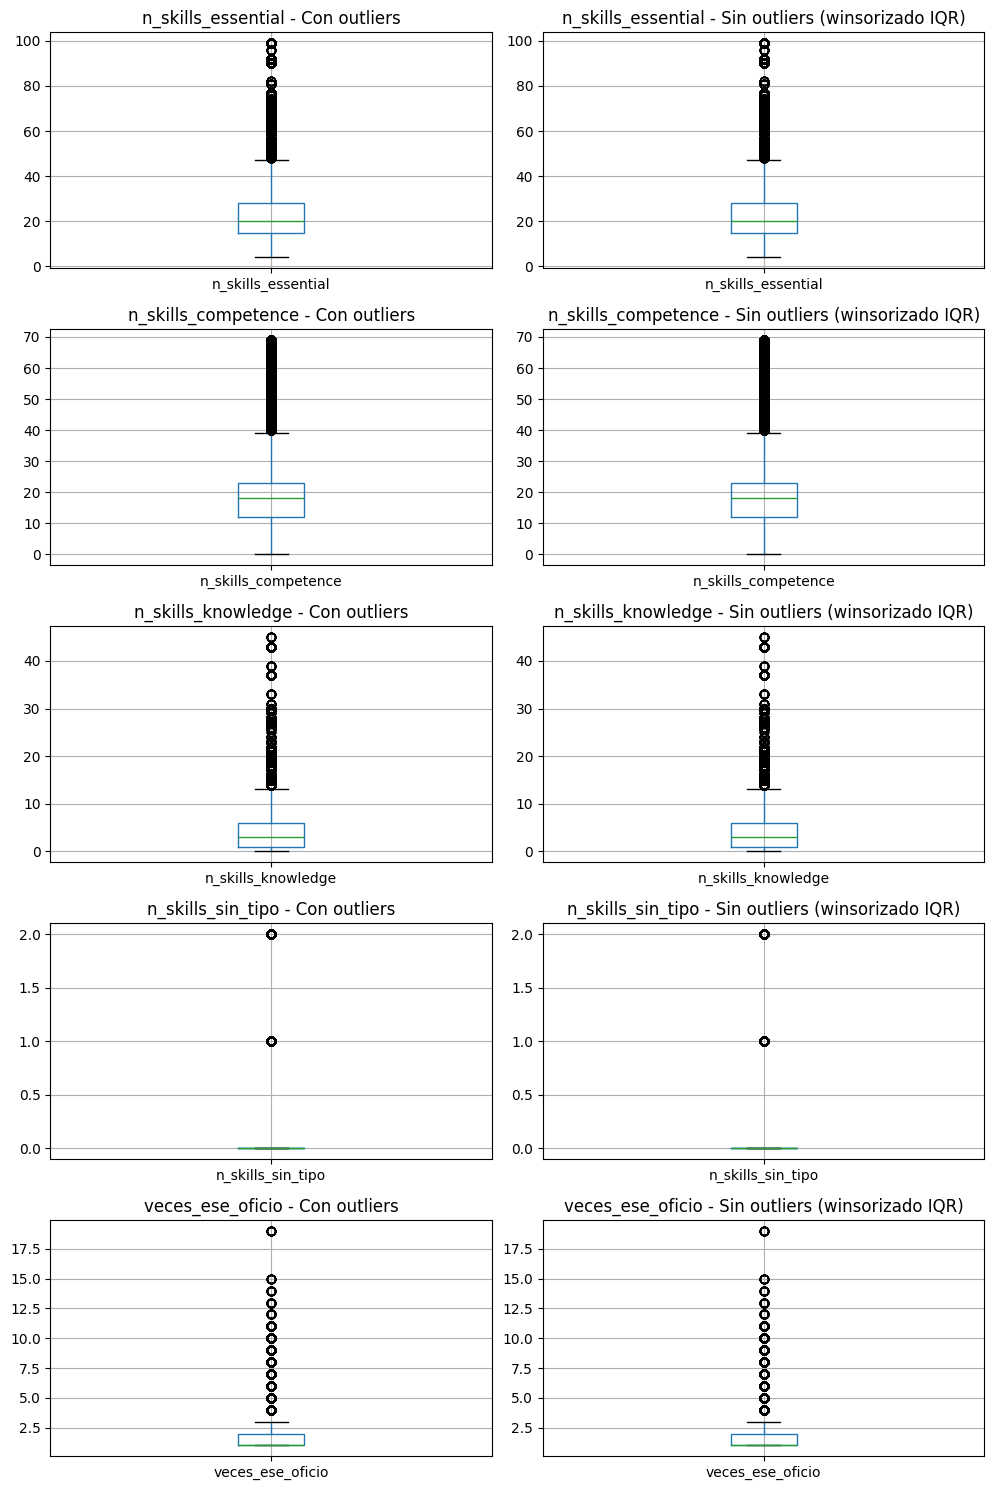

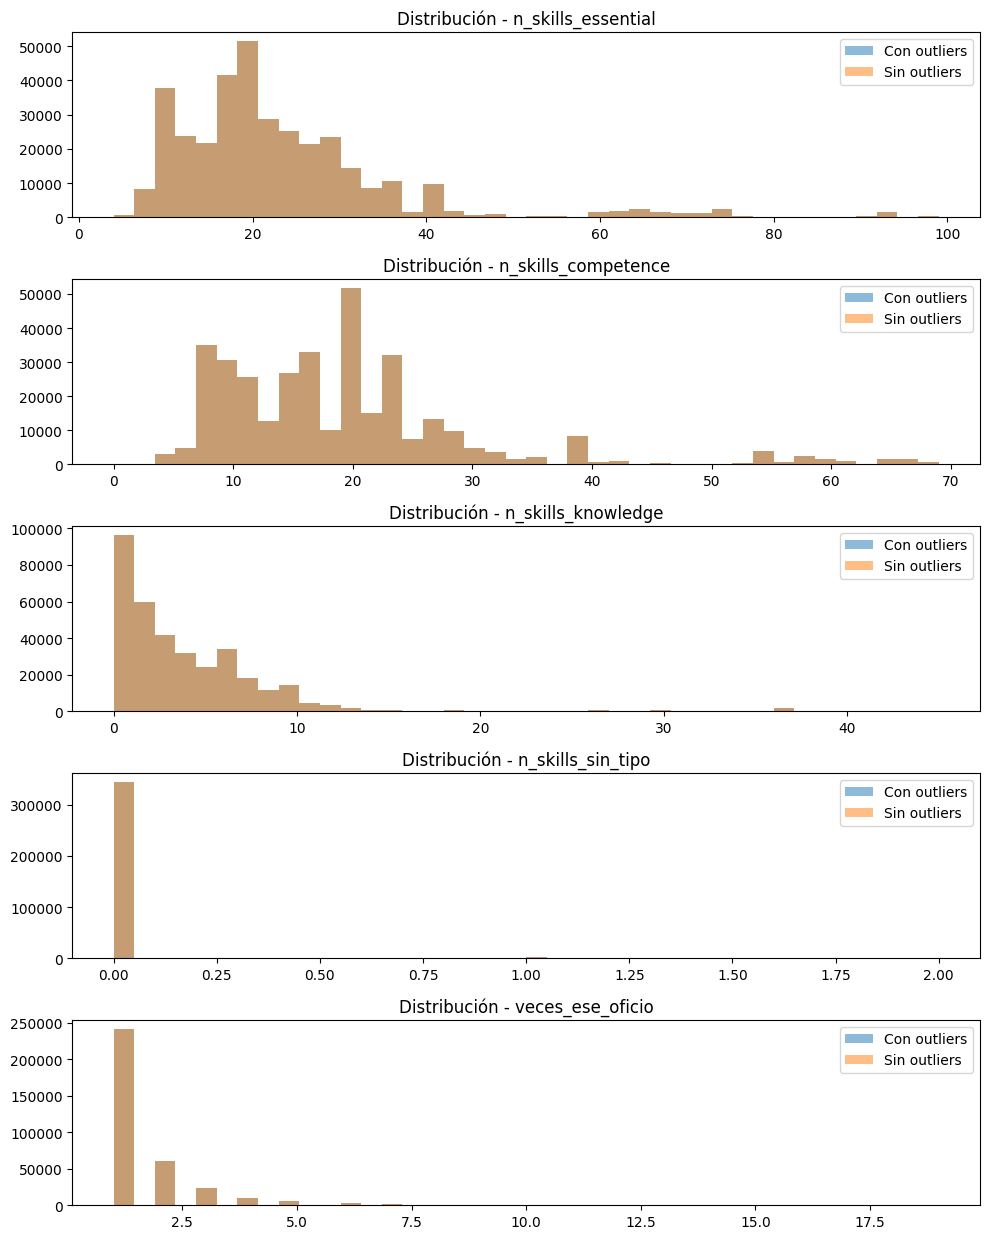

In [32]:
# Boxplots comparativos
n = len(vars_check)
if n > 0:
    fig, axes = plt.subplots(n, 2, figsize=(10, 3*n))
    if n == 1:
        axes = [axes]
    for i, c in enumerate(vars_check):
        ax1 = axes[i][0] if n > 1 else axes[0][0]
        ax2 = axes[i][1] if n > 1 else axes[0][1]
        df_con[[c]].boxplot(ax=ax1)
        ax1.set_title(f'{c} - Con outliers')
        df_sin[[c]].boxplot(ax=ax2)
        ax2.set_title(f'{c} - Sin outliers (winsorizado IQR)')
    plt.tight_layout()
    plt.show()

# Histogramas superpuestos
if n > 0:
    fig, axes = plt.subplots(n, 1, figsize=(10, 2.5*n))
    if n == 1:
        axes = [axes]
    for i, c in enumerate(vars_check):
        ax = axes[i]
        ax.hist(df_con[c].dropna(), bins=40, alpha=0.5, label='Con outliers')
        ax.hist(df_sin[c].dropna(), bins=40, alpha=0.5, label='Sin outliers')
        ax.set_title(f'Distribución - {c}')
        ax.legend()
    plt.tight_layout()
    plt.show()


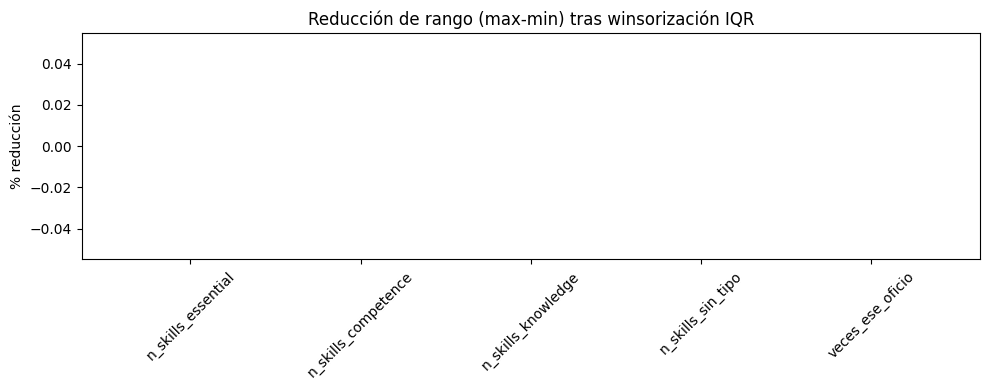

In [33]:
# Reducción de rango por variable
if not res.empty:
    plt.figure(figsize=(10,4))
    plt.bar(res['variable'], res['%_reduccion_rango'])
    plt.title('Reducción de rango (max-min) tras winsorización IQR')
    plt.ylabel('% reducción')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


### Análisis y recomendación

**Detalles observados:**
- Si el número de filas es **igual** entre ambas versiones, se confirma que **NO se eliminaron filas**, solo se aplicó `clip()` (winsorización).
- La tabla muestra cómo se acotan los valores máximos (y en ocasiones mínimos) sin tocar la mediana en la mayoría de los casos.
- Los *boxplots* permiten ver la compresión de las colas. Los histogramas muestran si la forma central se conserva.
- Si alguna variable muestra 0% de reducción, significa que no tenía valores fuera de los límites IQR o estaba excluida por las reglas.

**¿Con outliers, sin outliers o con ambos?**

| Uso | Recomendación | Explicación |
|---|---|---|
| **Análisis descriptivo, construcción de secuencias por persona (`S_p`), minería de transiciones** | **Conservar con outliers** (o revisar caso por caso) | Los extremos pueden representar trayectorias poco frecuentes pero válidas. Pueden contener la señal que se busca descubrir. |
| **Escalado, PCA, clustering, k-means, modelos basados en distancias** | **Usar sin outliers** | Las distancias euclídeas se ven fuertemente afectadas por colas largas. Winsorizar con IQR reduce ese efecto sin perder filas. |
| **Lo más adecuado para este proyecto** | **Usar ambos** | Generar la matriz `X` numérica desde `empleos_limpio_con_competencias_sin_outliers.csv`. Mantener la versión con outliers para el análisis descriptivo, validación de patrones y trazabilidad. |

**Regla práctica:** Si los gráficos muestran reducción importante en `n_skills_*` o `veces_ese_oficio`, lo correcto es usar la **versión sin outliers** para técnicas sensibles a escala/distancia. Si se desea preservar al máximo la variabilidad original para el análisis de secuencias, se puede priorizar la versión **con outliers** justificando la decisión en el informe.
